# 04 — Épuisement du combustible : k∞ et plutonium en fonction du taux de combustion

**Question** : comment le combustible d'un REP évolue-t-il pendant son séjour en réacteur, et combien de plutonium
produit-il ?

Jusqu'ici, tous mes calculs portaient sur du combustible neuf. Dans ce notebook, j'irradie la cellule crayon du
notebook 01 (UO₂ 4 %, eau à 580 K et 1000 ppm de bore) à puissance constante, jusqu'à un **taux de combustion** de
50 GWj/t, soit environ 3 ans et demi en réacteur. Je suis :
1. k∞ pendant l'irradiation, et l'**empoisonnement** par le xénon-135 et le samarium-149 ;
2. la consommation de l'U-235 et la **production de plutonium** (Pu-239, 240, 241, 242) ;
3. la part des fissions due au plutonium formé sur place.

**Point de départ** : l'exemple officiel *Pincell Depletion* d'OpenMC (`openmc.deplete`).

## 0. Rappel : transport et évolution

Pendant l'irradiation, la composition du combustible change :
- les **fissions** consomment l'U-235 (et plus tard le plutonium) et créent des **produits de fission** ;
- les **captures** transforment les noyaux : l'U-238 capture un neutron et devient du Pu-239,
  U-238 (n,γ) U-239 → (β⁻, 23 min) Np-239 → (β⁻, 2,4 j) Pu-239 ;
- les noyaux radioactifs **décroissent**.

Pour chaque nucléide $i$, on écrit un bilan (**équations de Bateman**) :

$$\frac{dN_i}{dt} = \underbrace{\sum_j \left(\sigma_{j\to i}\,\phi + \lambda_{j\to i}\right) N_j}_{\text{production}}
\;-\; \underbrace{\left(\sigma_{a,i}\,\phi + \lambda_i\right) N_i}_{\text{disparition}}$$

La difficulté, c'est que les taux de réaction $\sigma\phi$ dépendent du flux, qui dépend lui-même de la composition :
transport et évolution sont **couplés**. OpenMC les résout chacun leur tour :
1. un **calcul de transport** (Monte-Carlo, comme dans les notebooks précédents) donne les taux de réaction ;
2. on les suppose constants pendant un **pas de temps**, et on résout les équations de Bateman pour obtenir la
   nouvelle composition (méthode CRAM, une exponentielle de matrice) ;
3. on recommence avec la nouvelle composition.

C'est le schéma **prédicteur** (Euler explicite). Il existe des schémas plus précis (`CECMIntegrator` :
prédicteur-correcteur) qui refont un transport au milieu de chaque pas, mais ça double le temps de calcul.

**Unité de taux de combustion** : le MWj/kg (mégawatt-jour par kilogramme de métal lourd initial, ici l'uranium), qui
est la même chose que le GWj/t. 1 MWj/kg à 40 W/g correspond à 25 jours d'irradiation.

## 1. Préparation

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmc
import openmc.deplete
from openmc.mgxs import GROUP_STRUCTURES

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))
from src.style import appliquer_style, COULEURS
appliquer_style()
from src.modeles import modele_cellule_crayon
from src.calcul import epuiser

os.environ["PATH"] = str(Path(sys.executable).parent) + os.pathsep + os.environ["PATH"]
os.environ.setdefault(
    "OPENMC_CROSS_SECTIONS", str(Path.home() / "nuclear_data/endfb-viii.0-hdf5/cross_sections.xml")
)
assert Path(os.environ["OPENMC_CROSS_SECTIONS"]).exists(), "Données nucléaires introuvables (voir README)"

# Chaîne d'évolution simplifiée (voir section 3), téléchargée depuis openmc.org/data
CHAINE = Path.home() / "nuclear_data/chaines/chain_casl_pwr.xml"
assert CHAINE.exists(), "Chaîne d'évolution introuvable (voir README)"

DOSSIER_CALCUL = RACINE / "runs" / "04_epuisement"
DOSSIER_RESULTATS = RACINE / "results" / "04_epuisement"   # figures et tableaux de ce notebook
DOSSIER_CALCUL.mkdir(parents=True, exist_ok=True)
DOSSIER_RESULTATS.mkdir(parents=True, exist_ok=True)
print("OpenMC", openmc.__version__)

OpenMC 0.16.0


## 2. Modèle et normalisation en puissance

Je reprends la cellule crayon des notebooks précédents. Il faut lui ajouter deux informations :
- le **volume du combustible** : les taux de réaction calculés par OpenMC sont « par neutron source » ; pour les
  convertir en réactions par seconde, OpenMC les ramène à la puissance imposée, et il a besoin pour ça de connaître la
  quantité de combustible ;
- la **puissance** : j'impose une **puissance spécifique** de 40 W par gramme de métal lourd, valeur typique d'un REP.
  Je vérifie qu'elle donne une puissance linéique réaliste (≈ 180 W/cm pour un crayon moyen).

Statistique : 10 000 neutrons × 100 générations actives par transport (1 million d'histoires). C'est moins que dans le
notebook 01, car il faut refaire un transport à chaque pas : ≈ 100 pcm d'incertitude sur chaque k.

In [2]:
STATISTIQUE = dict(particules=10_000, generations=120, inactives=20, graine=1)
DENSITE_PUISSANCE = 40.0   # W par gramme de métal lourd initial


def modele_epuisement():
    # Cellule crayon dont le combustible porte son volume (nécessaire à la normalisation).
    # On remet à zéro la numérotation des objets OpenMC : chaque modèle a les mêmes identifiants,
    # quel que soit l'ordre d'exécution, ce que demande le cache des calculs.
    openmc.reset_auto_ids()
    modele, cellules = modele_cellule_crayon(**STATISTIQUE)
    combustible = cellules["combustible"].fill
    combustible.volume = cellules["combustible"].volume
    return modele, combustible


modele, combustible = modele_epuisement()
masse_ml = sum(combustible.get_mass(n) for n in combustible.get_nuclides() if n.startswith("U"))   # g
hauteur = 10.0   # cm, hauteur de la cellule (src/geometrie.py)
print(f"Volume du combustible : {combustible.volume:.3f} cm³ (hauteur {hauteur:.0f} cm)")
print(f"Masse de métal lourd  : {masse_ml:.2f} g, soit {masse_ml / hauteur:.2f} g/cm")
print(f"Puissance du crayon   : {DENSITE_PUISSANCE * masse_ml:.0f} W, "
      f"soit une puissance linéique de {DENSITE_PUISSANCE * masse_ml / hauteur:.0f} W/cm")

Volume du combustible : 5.271 cm³ (hauteur 10 cm)
Masse de métal lourd  : 48.32 g, soit 4.83 g/cm
Puissance du crayon   : 1933 W, soit une puissance linéique de 193 W/cm


## 3. La chaîne d'évolution

La **chaîne** décrit, pour chaque nucléide, ses réactions (capture, fission, (n,2n)…), ses décroissances (période,
produits) et, pour les noyaux fissiles, les **rendements de fission** (probabilité de former chaque produit de
fission). J'ai téléchargé deux chaînes sur le site d'OpenMC : la chaîne complète ENDF/B-VIII.0 (3 820 nucléides) et la
chaîne **simplifiée** pour les REP (228 nucléides retenus par le benchmark VERA pour leur importance neutronique).
J'utilise la simplifiée : elle suffit pour k∞ et les actinides, et le calcul est beaucoup plus rapide.

In [3]:
chaine = openmc.deplete.Chain.from_xml(CHAINE)
print(f"{len(chaine.nuclides)} nucléides, dont {sum(1 for n in chaine.nuclides if n.yield_data)} avec rendements de fission\n")


def periode(secondes):
    if secondes is None:
        return "stable"
    for unite, s in [("ans", 3.156e7), ("j", 86400), ("h", 3600), ("min", 60)]:
        if secondes >= s:
            return f"{secondes / s:.3g} {unite}"
    return f"{secondes:.3g} s"


print("Formation du plutonium à partir de l'U-238 :")
for nom in ["U238", "U239", "Np239", "Pu239"]:
    n = chaine[nom]
    capture = [r.target for r in n.reactions if r.type == "(n,gamma)"]
    decroissances = [f"{m.type} → {m.target}" for m in n.decay_modes if m.branching_ratio > 1e-3]
    print(f"  {nom:6s} période {periode(n.half_life):>12s} | capture (n,γ) → {capture[0] if capture else '-':8s}"
          f" | décroissance : {', '.join(decroissances) or '-'}")

print("\nPoisons neutroniques : produits de fission et précurseurs")
for nom in ["I135", "Xe135", "Nd149", "Pm149", "Sm149"]:
    n = chaine[nom]
    decroissances = [f"{m.type} → {m.target}" for m in n.decay_modes if m.branching_ratio > 1e-3]
    rendement = chaine["U235"].yield_data[0.0253].get(nom, 0.0) if chaine["U235"].yield_data else 0.0
    print(f"  {nom:6s} période {periode(n.half_life):>12s} | rendement direct U-235 (thermique) "
          f"{rendement:6.2%} | {', '.join(decroissances) or 'stable'}")

228 nucléides, dont 39 avec rendements de fission

Formation du plutonium à partir de l'U-238 :
  U238   période 4.47e+09 ans | capture (n,γ) → U239     | décroissance : alpha → Th234
  U239   période     23.4 min | capture (n,γ) → Np240_m1 | décroissance : beta- → Np239
  Np239  période       2.36 j | capture (n,γ) → Np240    | décroissance : beta- → Pu239
  Pu239  période 2.41e+04 ans | capture (n,γ) → Pu240    | décroissance : alpha → U235

Poisons neutroniques : produits de fission et précurseurs
  I135   période       6.57 h | rendement direct U-235 (thermique)  6.28% | beta- → Xe135, beta- → Xe135_m1
  Xe135  période       9.14 h | rendement direct U-235 (thermique)  0.08% | beta- → Cs135
  Nd149  période       1.73 h | rendement direct U-235 (thermique)  1.08% | beta- → Pm149
  Pm149  période       2.21 j | rendement direct U-235 (thermique)  0.00% | beta- → Sm149
  Sm149  période       stable | rendement direct U-235 (thermique)  0.00% | stable


## 4. Calendrier d'irradiation

Le choix des pas est un compromis :
- les **premiers pas sont courts** (0,1 puis 0,4 et 0,5 MWj/kg, soit 2,5 à 12,5 jours) : le xénon-135 atteint son
  équilibre en environ 2 jours, et le samarium-149 en quelques semaines ; avec des pas longs, je raterais cette chute
  rapide de k∞ ;
- ensuite, des pas de **2 MWj/kg** (50 jours), la valeur conseillée par l'exemple officiel pour le schéma prédicteur.

In [4]:
PAS = [0.1, 0.4, 0.5, 1.0, 1.0] + [2.0] * 23 + [1.0]   # MWj/kg
taux_combustion = np.concatenate([[0.0], np.cumsum(PAS)])
print(f"{len(PAS)} pas, soit {len(PAS) + 1} calculs de transport")
print(f"Taux de combustion final : {taux_combustion[-1]:.0f} MWj/kg, "
      f"soit {taux_combustion[-1] * 1000 / DENSITE_PUISSANCE:.0f} jours ≈ "
      f"{taux_combustion[-1] * 1000 / DENSITE_PUISSANCE / 365.25:.1f} ans à {DENSITE_PUISSANCE:.0f} W/g")

29 pas, soit 30 calculs de transport
Taux de combustion final : 50 MWj/kg, soit 1250 jours ≈ 3.4 ans à 40 W/g


## 5. Calcul

`epuiser` (dans `src/calcul.py`) crée un `openmc.deplete.CoupledOperator`, qui relie le modèle, la chaîne et le
solveur de transport, puis lance l'intégration en temps. Comme pour les autres calculs du projet, le résultat est gardé
en cache : relancer le notebook ne refait pas le calcul si rien n'a changé.

**Comment sont calculés les taux de réaction ?** C'est le point qui m'a posé le plus de problèmes. Il y a trois
possibilités :
- mode `direct` (par défaut) : OpenMC compte pendant le transport chaque réaction de chaque nucléide de la chaîne.
  C'est exact, mais lent ;
- mode `flux` : OpenMC ne compte que le **flux par groupe d'énergie** dans le combustible (361 groupes, structure SHEM
  conçue pour les REP), puis applique à chaque groupe la section efficace en énergie continue, comme si le flux était
  **plat** dans le groupe. C'est plus de deux fois plus rapide, et c'est ce que j'avais choisi au départ ;
- mode **mixte** : le mode `flux`, mais avec les **captures et fissions des principaux actinides** comptées
  directement.

> **L'erreur que j'ai faite, et comment je l'ai trouvée.** Mon premier calcul complet, en mode `flux`, donnait
> 20,7 kg/t de plutonium à 50 MWj/kg. Ça m'a paru trop : un combustible usé de REP en contient plutôt 11 à 13 kg/t.
> J'avais pourtant vérifié le mode `flux` avant de lancer le calcul… mais seulement sur k∞, au début de l'irradiation,
> où il donnait le bon résultat. En comparant avec le mode `direct` sur les premiers pas, j'ai trouvé que le mode
> `flux` surestimait les captures de l'U-238 d'environ 30 %. La raison : supposer un flux plat dans chaque groupe
> revient à ignorer l'**autoprotection**. Dans une résonance étroite de l'U-238, le flux réel s'effondre dans la
> pastille (le creux du spectre du notebook 01), donc le vrai taux de capture est bien plus faible que celui calculé
> avec un flux plat. La documentation d'OpenMC le signale d'ailleurs, et propose le mode mixte que j'utilise
> maintenant. La section 6.5 détaille la comparaison des trois modes.

Durée : ≈ 35 minutes la première fois. Pour suivre l'avancement pendant le calcul, depuis un terminal à la racine du
projet : `tail -f runs/04_epuisement/principal/progression.log` (une ligne par transport terminé, avec le temps
restant).

In [5]:
ACTINIDES = ["U234", "U235", "U236", "U238", "Np237", "Np239",
             "Pu238", "Pu239", "Pu240", "Pu241", "Pu242", "Am241"]
OPTIONS_FLUX = {"reaction_rate_mode": "flux",
                "reaction_rate_opts": {"energies": GROUP_STRUCTURES["SHEM-361"]}}
OPTIONS_MIXTE = {"reaction_rate_mode": "flux",
                 "reaction_rate_opts": {"energies": GROUP_STRUCTURES["SHEM-361"],
                                        "reactions": ["(n,gamma)", "fission"],   # comptabilisées directement…
                                        "nuclides": ACTINIDES}}                   # … pour ces nucléides

calcul = epuiser(modele, CHAINE, PAS, DOSSIER_CALCUL / "principal", options_operateur=OPTIONS_MIXTE,
                 power_density=DENSITE_PUISSANCE, timestep_units="MWd/kg")
print(f"Calcul : {calcul['duree']:.0f} s" + (" (résultat réutilisé)" if calcul["reutilise"] else ""))

resultats = openmc.deplete.Results(calcul["resultats"])
MAT = list(resultats[0].index_mat)[0]   # identifiant du combustible (seul matériau épuisable)
jours, k = resultats.get_keff(time_units="d")
bu = jours * DENSITE_PUISSANCE / 1000   # taux de combustion, MWj/kg
k_moy, k_sig = k[:, 0], k[:, 1]
print(f"{len(bu)} états, de 0 à {bu[-1]:.0f} MWj/kg")

Calcul : 0 s (résultat réutilisé)


30 états, de 0 à 50 MWj/kg


## 6. Résultats

### 6.1 k∞ en fonction du taux de combustion

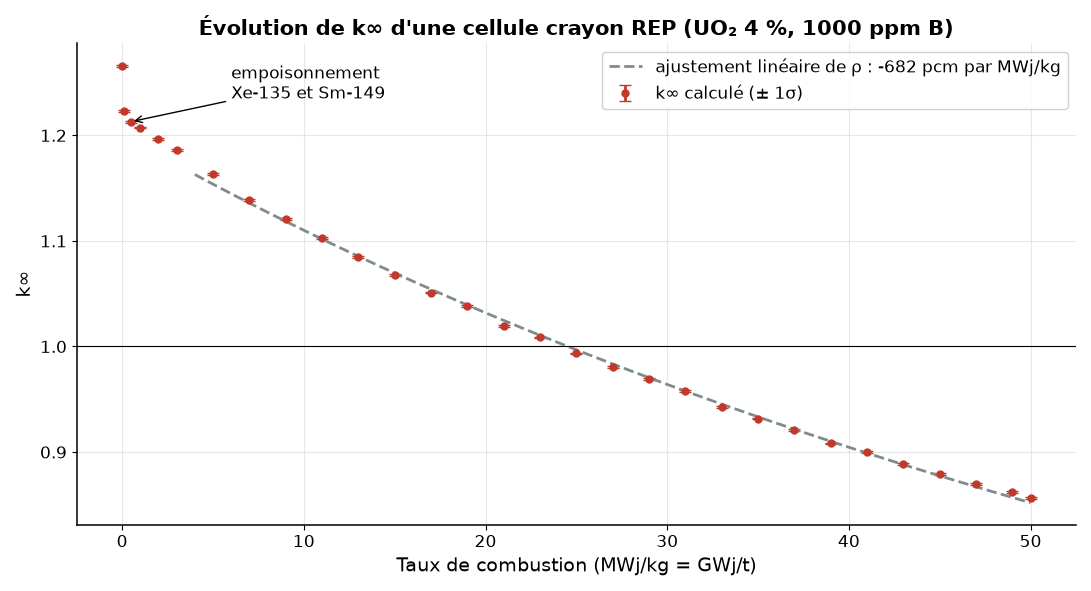

k∞ initial            : 1.26557 ± 0.00088
k∞ à 3 MWj/kg (poisons à l'équilibre) : 1.18603 ± 0.00086  (Δρ = -5299 ± 82 pcm)
k∞ final (50 MWj/kg) : 0.85662 ± 0.00078
Pente de la réactivité après 4 MWj/kg : -682 pcm par MWj/kg
k∞ passe sous 1 vers 24 MWj/kg (à 1000 ppm de bore, sans fuites)


In [6]:
rho = (k_moy - 1) / k_moy * 1e5
rho_sig = k_sig / k_moy**2 * 1e5

# Pente de la partie quasi linéaire (après la mise à l'équilibre des poisons), ajustement pondéré
lin = bu >= 4
pente, origine = np.polyfit(bu[lin], rho[lin], 1, w=1 / rho_sig[lin])

fig, ax = plt.subplots(figsize=(11, 6))
ax.errorbar(bu, k_moy, yerr=k_sig, fmt="o", ms=5, color=COULEURS["rouge"], label="k∞ calculé (± 1σ)")
x = np.linspace(4, bu[-1], 50)
ax.plot(x, 1e5 / (1e5 - (origine + pente * x)), "--", color=COULEURS["gris"],
        label=f"ajustement linéaire de ρ : {pente:.0f} pcm par MWj/kg")
ax.axhline(1, color="k", lw=0.8)
ax.annotate("empoisonnement\nXe-135 et Sm-149", xy=(bu[2], k_moy[2]), xytext=(6, 1.235),
            arrowprops=dict(arrowstyle="->"), fontsize=12)
ax.set_xlabel("Taux de combustion (MWj/kg = GWj/t)")
ax.set_ylabel("k∞")
ax.set_title("Évolution de k∞ d'une cellule crayon REP (UO₂ 4 %, 1000 ppm B)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "k_burnup.png")
plt.show()

print(f"k∞ initial            : {k_moy[0]:.5f} ± {k_sig[0]:.5f}")
i_eq = np.searchsorted(bu, 3.0)
print(f"k∞ à {bu[i_eq]:.0f} MWj/kg (poisons à l'équilibre) : {k_moy[i_eq]:.5f} ± {k_sig[i_eq]:.5f}  "
      f"(Δρ = {rho[i_eq] - rho[0]:.0f} ± {np.hypot(rho_sig[i_eq], rho_sig[0]):.0f} pcm)")
print(f"k∞ final ({bu[-1]:.0f} MWj/kg) : {k_moy[-1]:.5f} ± {k_sig[-1]:.5f}")
print(f"Pente de la réactivité après 4 MWj/kg : {pente:.0f} pcm par MWj/kg")
if k_moy[-1] < 1:
    i = np.argmax(k_moy < 1)
    bu_critique = np.interp(1.0, [k_moy[i], k_moy[i - 1]], [bu[i], bu[i - 1]])
    print(f"k∞ passe sous 1 vers {bu_critique:.0f} MWj/kg (à 1000 ppm de bore, sans fuites)")

**Ce que j'observe.**
- **Chute initiale** : k∞ passe de 1,2656 à 1,2231 en 2,5 jours seulement (≈ −2 700 pcm), puis continue de baisser
  plus vite que la suite pendant quelques semaines. C'est l'**empoisonnement** par les produits de fission xénon-135
  puis samarium-149 (section 6.2), qui atteignent une concentration d'équilibre. Au total, entre 0 et 3 MWj/kg, la
  réactivité perd ≈ 5 300 pcm, dont environ 2 000 pcm d'usure « normale » du combustible (3 MWj/kg × ≈ 680 pcm) : le
  reste, ≈ 3 300 pcm, vient des deux poisons.
- **Décroissance presque linéaire** ensuite : ≈ −680 pcm par MWj/kg. L'U-235 disparaît, des produits de fission
  absorbants s'accumulent, et le plutonium formé ne compense qu'en partie. La pente s'adoucit un peu en fin
  d'irradiation (les points passent au-dessus de la droite), car le plutonium participe de plus en plus aux fissions.
- **k∞ passe sous 1 vers 24 MWj/kg.** Ça peut paraître très tôt, mais ce n'est **pas** le taux de combustion
  auquel on décharge un vrai combustible : ici le bore reste à 1000 ppm (en réacteur, on le dilue jusqu'à ≈ 0 ppm en
  fin de cycle), il n'y a pas de fuites, et un cœur est géré **par lots** (un tiers ou un quart du combustible
  renouvelé à chaque arrêt) : les assemblages neufs, très réactifs, compensent les plus usés, ce qui permet de
  décharger le combustible vers 45–55 GWj/t.

### 6.2 Empoisonnement par le xénon-135 et le samarium-149

Ces deux produits de fission ont des sections efficaces de capture thermique énormes (≈ 2,6 millions de barns pour le
Xe-135, ≈ 40 000 barns pour le Sm-149). Ils sont surtout formés par **décroissance** d'autres produits de fission
(I-135, Pm-149), et disparaissent par **capture** (et par décroissance pour le Xe-135) : leur concentration atteint un
équilibre.

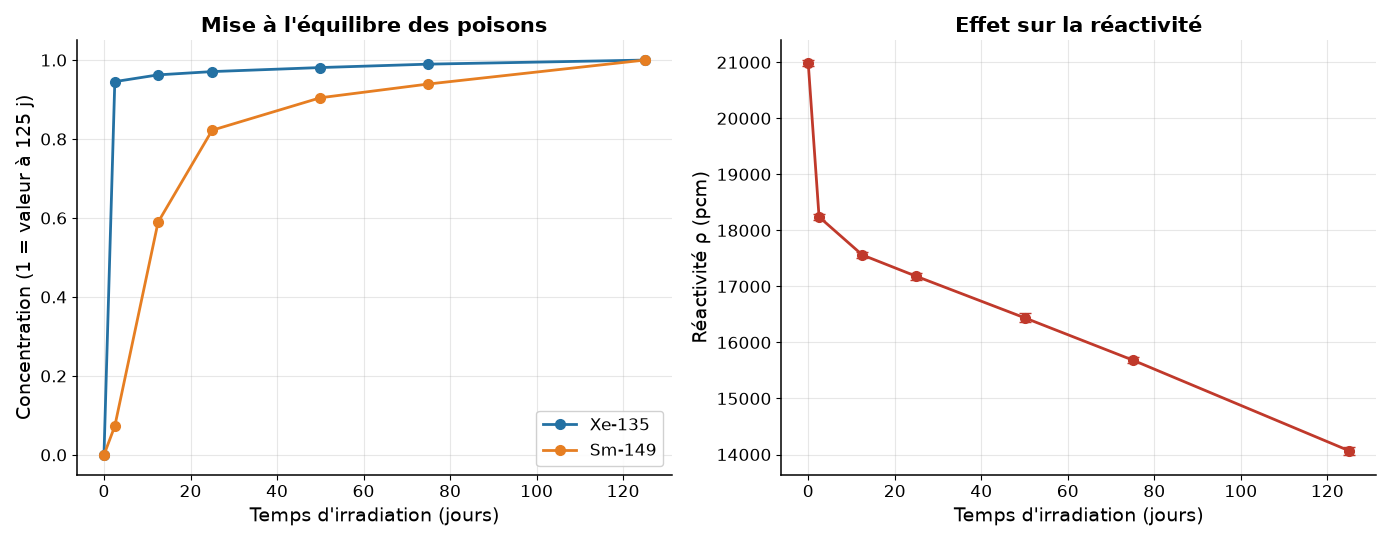

Xe135 : 90 % de la concentration à 125 jours atteinte avant 2.5 jours
Sm149 : 90 % de la concentration à 125 jours atteinte avant 50.0 jours


In [7]:
debut = jours <= 130   # jusqu'à 5 MWj/kg (125 jours)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
for nuc, couleur in [("Xe135", COULEURS["bleu"]), ("Sm149", COULEURS["orange"])]:
    _, n = resultats.get_atoms(MAT, nuc, nuc_units="atom/b-cm", time_units="d")
    ax1.plot(jours[debut], n[debut] / n[debut][-1], "o-", color=couleur, label=nuc.replace("135", "-135").replace("149", "-149"))
ax1.set_xlabel("Temps d'irradiation (jours)")
ax1.set_ylabel("Concentration (1 = valeur à 125 j)")
ax1.set_title("Mise à l'équilibre des poisons")
ax1.legend()

ax2.errorbar(jours[debut], rho[debut], yerr=rho_sig[debut], fmt="o-", color=COULEURS["rouge"])
ax2.set_xlabel("Temps d'irradiation (jours)")
ax2.set_ylabel("Réactivité ρ (pcm)")
ax2.set_title("Effet sur la réactivité")
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "xenon_samarium.png")
plt.show()

for nuc in ["Xe135", "Sm149"]:
    _, n = resultats.get_atoms(MAT, nuc, nuc_units="atom/b-cm", time_units="d")
    i90 = np.argmax(n >= 0.9 * n[debut][-1])
    print(f"{nuc} : 90 % de la concentration à 125 jours atteinte avant {jours[i90]:.1f} jours")

**Ce que j'observe.**
- Le **xénon-135** atteint 90 % de son niveau d'équilibre avant 2,5 jours (le premier pas) : il est formé surtout par
  décroissance de l'iode-135 (période 6,6 h) et disparaît par capture (sa propre période est de 9,1 h). Avec des
  constantes de temps de quelques heures, l'équilibre est atteint en un à deux jours, et il coûte ≈ 2 700 pcm.
- Le **samarium-149** est **stable** : il ne disparaît que par capture, et le prométhium-149 qui le forme a une période
  de 2,2 jours. Son équilibre est donc beaucoup plus lent : 90 % en ≈ 50 jours.
- À droite, la réactivité chute brutalement pendant les 2,5 premiers jours (xénon), puis baisse plus vite qu'ensuite
  jusqu'à ≈ 50 jours (samarium), avant de rejoindre la pente régulière de l'usure du combustible.

C'est pour ça que les premiers pas doivent être courts : avec un premier pas de 50 jours, le calcul aurait supposé un
combustible sans poisons pendant tout ce pas, donc surestimé le flux thermique et l'usure.

### 6.3 Noyaux lourds : consommation de l'uranium et production de plutonium

Je rapporte les masses à la masse initiale de métal lourd, pour avoir des **kg par tonne** (kg/t) d'uranium initial,
l'unité qu'on trouve habituellement pour les combustibles usés.

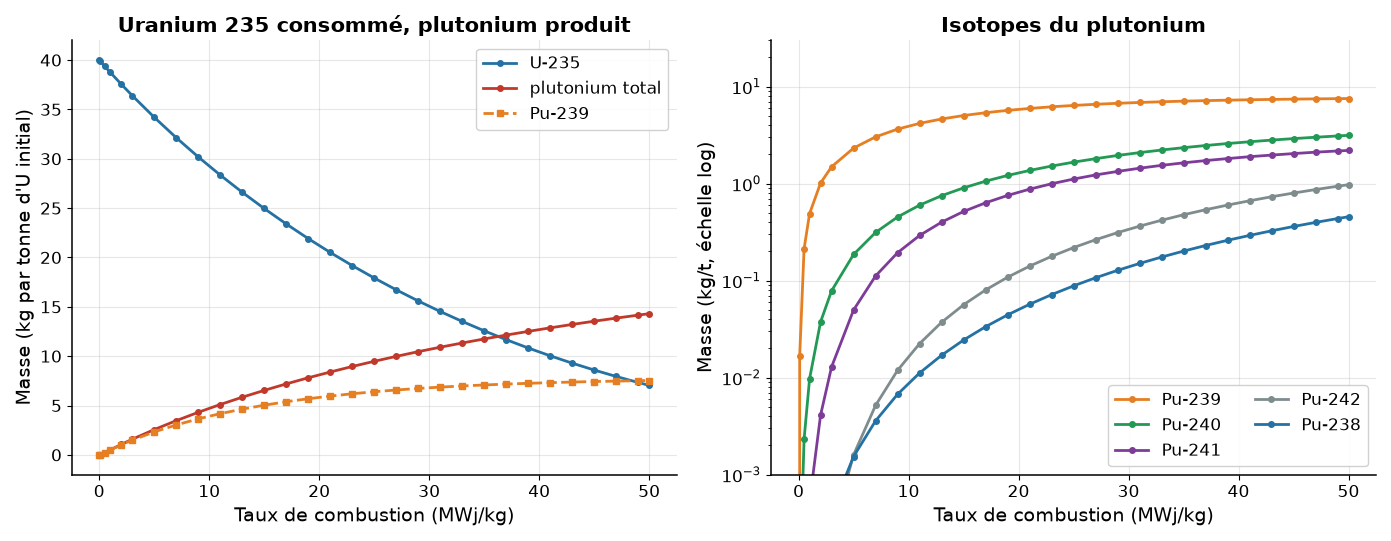

U-235 : 40.0 → 7.0 kg/t (enrichissement résiduel ≈ 0.76 %)
U-238 consommé : 41.7 kg/t
Plutonium total en fin d'irradiation : 14.30 kg/t
Américium 241 : 0.063 kg/t ; neptunium 237 : 0.808 kg/t


In [8]:
NUCLEIDES = ["U235", "U236", "U238", "Np237", "Pu238", "Pu239", "Pu240", "Pu241", "Pu242", "Am241"]
masses = pd.DataFrame({"bu_MWj_kg": bu, "jours": jours, "k_inf": k_moy, "sigma_k": k_sig})
for nuc in NUCLEIDES:
    _, m = resultats.get_mass(MAT, nuc, mass_units="g", time_units="d")
    masses[nuc] = m / masse_ml * 1000   # kg par tonne de métal lourd initial
pu = ["Pu238", "Pu239", "Pu240", "Pu241", "Pu242"]
masses["Pu_total"] = masses[pu].sum(axis=1)
masses.round(5).to_csv(DOSSIER_RESULTATS / "evolution.csv", index=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
ax1.plot(bu, masses["U235"], "o-", ms=4, color=COULEURS["bleu"], label="U-235")
ax1.plot(bu, masses["Pu_total"], "o-", ms=4, color=COULEURS["rouge"], label="plutonium total")
ax1.plot(bu, masses["Pu239"], "s--", ms=4, color=COULEURS["orange"], label="Pu-239")
ax1.set_xlabel("Taux de combustion (MWj/kg)")
ax1.set_ylabel("Masse (kg par tonne d'U initial)")
ax1.set_title("Uranium 235 consommé, plutonium produit")
ax1.legend()

for nuc, couleur in zip(["Pu239", "Pu240", "Pu241", "Pu242", "Pu238"],
                        [COULEURS["orange"], COULEURS["vert"], COULEURS["violet"], COULEURS["gris"], COULEURS["bleu"]]):
    ax2.plot(bu, masses[nuc], "o-", ms=4, color=couleur, label=nuc.replace("Pu", "Pu-"))
ax2.set_yscale("log")
ax2.set_ylim(1e-3, 30)
ax2.set_xlabel("Taux de combustion (MWj/kg)")
ax2.set_ylabel("Masse (kg/t, échelle log)")
ax2.set_title("Isotopes du plutonium")
ax2.legend(ncol=2)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "noyaux_lourds.png")
plt.show()

fin = masses.iloc[-1]
print(f"U-235 : {masses['U235'].iloc[0]:.1f} → {fin['U235']:.1f} kg/t "
      f"(enrichissement résiduel ≈ {fin['U235'] / (fin['U235'] + fin['U238'] + fin['U236']) * 100:.2f} %)")
print(f"U-238 consommé : {masses['U238'].iloc[0] - fin['U238']:.1f} kg/t")
print(f"Plutonium total en fin d'irradiation : {fin['Pu_total']:.2f} kg/t")
print(f"Américium 241 : {fin['Am241']:.3f} kg/t ; neptunium 237 : {fin['Np237']:.3f} kg/t")

**Ce que j'observe.**
- **U-235** : de 40 à 7,0 kg/t, soit un enrichissement résiduel de 0,76 %, de l'ordre des ≈ 0,8 % mesurés sur les
  combustibles usés de REP : un peu plus de 80 % de l'U-235 a été consommé.
- **Plutonium** : 14,3 kg/t en fin d'irradiation (1,4 % du métal lourd). C'est encore un peu plus que les valeurs
  typiques (≈ 11 à 13 kg/t), mais bien plus raisonnable que les 20,7 kg/t de mon premier calcul. Une partie de l'écart
  vient de mon hypothèse de bore constant à 1000 ppm : le bore absorbe surtout les neutrons thermiques, ce qui durcit le
  spectre et favorise les captures dans les résonances de l'U-238. En réacteur, la concentration baisse au cours du
  cycle.
- Le **Pu-239** plafonne vers 7,5 kg/t : au-delà de ≈ 30 MWj/kg, il disparaît (fission, capture) presque aussi vite
  qu'il se forme. Les isotopes plus lourds continuent d'augmenter : chacun est formé par capture sur le précédent
  (Pu-239 → 240 → 241 → 242), d'où leur apparition décalée sur l'échelle logarithmique.
- 41,7 kg/t d'U-238 ont disparu, surtout par capture : c'est de là que vient le plutonium.

### 6.4 Vecteur isotopique du plutonium et part des fissions dues au plutonium

Le **vecteur isotopique** donne la composition du plutonium. Les isotopes impairs (Pu-239, Pu-241) sont **fissiles**
avec des neutrons thermiques ; les isotopes pairs (Pu-238, 240, 242) ne le sont pas. Plus le combustible est irradié,
plus le Pu-239 capture des neutrons pour former du Pu-240, puis du Pu-241 et du Pu-242 : la « qualité » du plutonium
(sa part fissile) baisse.

In [9]:
etats = [np.argmin(np.abs(bu - b)) for b in (10, 30, 50)]   # états calculés les plus proches
vecteur = pd.DataFrame([masses.loc[i, pu] / masses.loc[i, "Pu_total"] * 100 for i in etats],
                       index=[f"{bu[i]:.0f} MWj/kg" for i in etats])
vecteur["fissile (239+241)"] = vecteur["Pu239"] + vecteur["Pu241"]
vecteur.round(1).to_csv(DOSSIER_RESULTATS / "vecteur_plutonium.csv")
print("Vecteur isotopique du plutonium (% massique) :")
print(vecteur.round(1).to_string())

Vecteur isotopique du plutonium (% massique) :
           Pu238  Pu239  Pu240  Pu241  Pu242  fissile (239+241)
9 MWj/kg     0.2   84.6   10.5    4.5    0.3               89.1
29 MWj/kg    1.2   64.4   18.7   12.8    3.0               77.1
50 MWj/kg    3.2   52.7   22.0   15.4    6.8               68.0


**Part des fissions par nucléide.** Je voulais savoir quels noyaux fissionnent au cours de l'irradiation. Ma première
idée était de relire les taux de réaction enregistrés pendant l'épuisement, mais OpenMC ne les sauvegarde pas par
défaut. Plutôt que de relancer 35 minutes de calcul, je reprends la composition du combustible enregistrée à quelques
taux de combustion (`Results.export_to_materials`) et je relance sur chacune un simple calcul de transport, avec un
tally du taux de fission **par nucléide**. Ça fait six calculs courts, gardés en cache comme les autres.

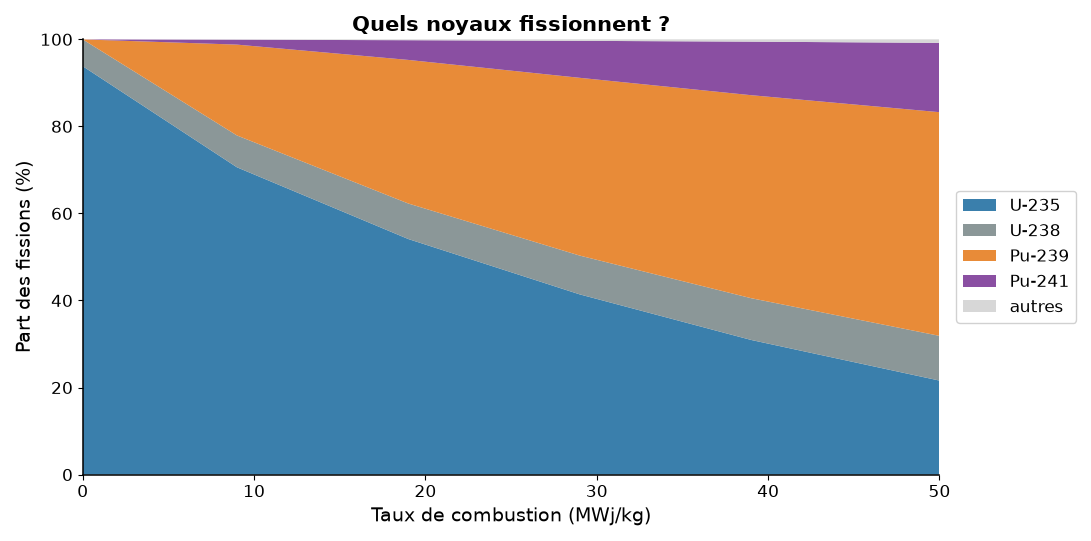

,MWj/kg,U235,U238,Pu239,Pu241,k∞ (transport seul),autres,plutonium
0,0.0,93.8,6.2,0.0,0.0,1.2663,0.0,0.0
1,9.0,70.6,7.3,20.9,1.1,1.1212,0.1,22.0
2,19.0,54.1,8.2,33.0,4.5,1.0370,0.2,37.5
3,29.0,41.4,8.9,40.8,8.5,0.9682,0.3,49.3
4,39.0,30.9,9.6,46.6,12.3,0.9088,0.5,58.9
5,50.0,21.6,10.3,51.4,15.9,0.8575,0.8,67.3


In [10]:
import warnings
from openmc.mixin import IDWarning
from src.calcul import calculer_k

FISSILES = ["U235", "U238", "Pu239", "Pu241"]
# Nucléides disponibles dans la bibliothèque de sections efficaces (ceux de la chaîne n'en ont pas tous)
bibliotheque = openmc.data.DataLibrary.from_xml()
avec_donnees = sorted({m for lib in bibliotheque.libraries if lib["type"] == "neutron" for m in lib["materials"]})

lignes = []
for i in [np.argmin(np.abs(bu - b)) for b in (0, 10, 20, 30, 40, 50)]:
    modele_i, combustible_neuf = modele_epuisement()
    cellules_i = {c.name: c for c in modele_i.geometry.get_all_cells().values()}
    # Les matériaux relus reprennent les identifiants du calcul d'épuisement (1, 2…), déjà utilisés par le
    # modèle neuf : c'est voulu (on remplace son combustible), on masque donc l'avertissement correspondant.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", IDWarning)
        combustible_i = next(m for m in resultats.export_to_materials(
            i, nuc_with_data=avec_donnees, path=DOSSIER_CALCUL / "principal" / "materials.xml") if str(m.id) == MAT)
    cellules_i["combustible"].fill = combustible_i
    modele_i.materials = openmc.Materials([combustible_i] + [m for m in modele_i.materials if not m.depletable])
    tally = openmc.Tally(name="fissions")
    tally.filters = [openmc.CellFilter([cellules_i["combustible"]])]
    tally.nuclides = FISSILES + ["total"]
    tally.scores = ["fission"]
    modele_i.tallies = openmc.Tallies([tally])
    r = calculer_k(modele_i, DOSSIER_CALCUL / "fissions" / f"etat_{i:02d}")
    with openmc.StatePoint(r["statepoint"]) as sp:
        taux = sp.get_tally(name="fissions").get_values(scores=["fission"]).ravel()   # FISSILES puis total
    lignes.append({"MWj/kg": bu[i], **{n: t / taux[-1] * 100 for n, t in zip(FISSILES, taux)},
                   "k∞ (transport seul)": r["k"]})
parts = pd.DataFrame(lignes)
parts["autres"] = 100 - parts[FISSILES].sum(axis=1)
parts["plutonium"] = parts["Pu239"] + parts["Pu241"]
parts.round(2).to_csv(DOSSIER_RESULTATS / "parts_fissions.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.stackplot(parts["MWj/kg"], *[parts[n] for n in FISSILES + ["autres"]],
             labels=["U-235", "U-238", "Pu-239", "Pu-241", "autres"],
             colors=[COULEURS["bleu"], COULEURS["gris"], COULEURS["orange"], COULEURS["violet"], "lightgray"],
             alpha=0.9)
ax.set_xlim(0, parts["MWj/kg"].max())
ax.set_ylim(0, 100)
ax.set_xlabel("Taux de combustion (MWj/kg)")
ax.set_ylabel("Part des fissions (%)")
ax.set_title("Quels noyaux fissionnent ?")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.grid(False)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "fissions.png")
plt.show()
parts.round({**{c: 1 for c in parts.columns}, "k∞ (transport seul)": 4})

**Ce que j'observe.**
- **Vecteur isotopique** : la part de Pu-239 passe de 85 % à 9 MWj/kg à 53 % à 50 MWj/kg, et la part fissile
  (Pu-239 + Pu-241) de 89 % à 68 %. Le vecteur obtenu en fin d'irradiation (≈ 53 / 22 / 15 / 7 % pour les Pu-239 / 240
  / 241 / 242, et 3 % de Pu-238) correspond à ce qu'on trouve dans un combustible UO₂ usé de REP : c'est ce plutonium
  qu'on recycle dans le combustible MOX.
- **Fissions** : au début, 94 % des fissions sont celles de l'U-235 et 6 % celles de l'U-238 (fissions rapides,
  au-dessus de ≈ 1 MeV). Le plutonium formé sur place prend vite le relais : **22 % des fissions dès 9 MWj/kg, la
  moitié vers 30 MWj/kg, et les deux tiers à 50 MWj/kg**. C'est le résultat qui m'a le plus surpris : un REP « à
  l'uranium » produit, en fin de vie de son combustible, la plus grande partie de son énergie en fissionnant du
  plutonium.
- La part de l'U-238 augmente un peu (6 → 10 %) : le spectre se durcit, car le plutonium absorbe beaucoup les
  neutrons thermiques.
- Vérification : les k∞ de ces six transports (dernière colonne) sont cohérents avec ceux du calcul d'épuisement
  (section 6.1) aux mêmes taux de combustion.

### 6.5 Vérification : modes `flux`, mixte et `direct`

Pour valider le mode mixte et comprendre mon erreur de départ, je refais les trois premiers pas (jusqu'à 1 MWj/kg) en
mode `direct`, la référence exacte, avec les mêmes réglages. Je compare ce qui a été consommé ou produit pendant ce
premier MWj/kg dans les trois modes. Mon premier calcul complet en mode `flux` pur est relu depuis le cache pour la
comparaison à 50 MWj/kg.

In [11]:
def relancer(mode, pas, dossier):
    m, _ = modele_epuisement()
    return epuiser(m, CHAINE, pas, DOSSIER_CALCUL / dossier, options_operateur=mode,
                   power_density=DENSITE_PUISSANCE, timestep_units="MWd/kg")


calculs = {
    "direct (référence)": relancer({"reaction_rate_mode": "direct"}, PAS[:3], "verification_direct"),
    "flux pur": relancer(OPTIONS_FLUX, PAS, "flux_pur"),
    "mixte (retenu)": calcul,
}
lignes = []
for nom, c in calculs.items():
    r = openmc.deplete.Results(c["resultats"])
    mat = list(r[0].index_mat)[0]
    _, kk = r.get_keff()
    ligne = {"mode": nom, "k∞ à 1 MWj/kg": kk[3, 0], "σ": kk[3, 1]}
    for nuc in ["U235", "U238", "Pu239", "Xe135"]:
        _, n_at = r.get_atoms(mat, nuc)
        ligne[f"Δ{nuc} (10¹⁹ at.)"] = (n_at[3] - n_at[0]) / 1e19
    if len(r) == len(bu):
        _, m_pu = r.get_mass(mat, "Pu239", mass_units="g")
        ligne["Pu-239 à 50 MWj/kg (kg/t)"] = m_pu[-1] / masse_ml * 1000
        ligne["k∞ à 50 MWj/kg"] = kk[-1, 0]
    lignes.append(ligne)
comparaison = pd.DataFrame(lignes).set_index("mode")
reference = comparaison.loc["direct (référence)"]
for nuc in ["U238", "Pu239"]:
    comparaison[f"écart Δ{nuc}"] = (comparaison[f"Δ{nuc} (10¹⁹ at.)"] / reference[f"Δ{nuc} (10¹⁹ at.)"] - 1) * 100
comparaison.round(4)

,k∞ à 1 MWj/kg,σ,ΔU235 (10¹⁹ at.),ΔU238 (10¹⁹ at.),ΔPu239 (10¹⁹ at.),ΔXe135 (10¹⁹ at.),Pu-239 à 50 MWj/kg (kg/t),k∞ à 50 MWj/kg,écart ΔU238,écart ΔPu239
mode,,,,,,,,,,
direct (référence),1.2072,0.0009,-15.3678,-8.1937,5.9876,0.0059,NaN,NaN,0.0000,0.0000
flux pur,1.2076,0.0010,-15.3438,-10.4674,7.8537,0.0060,12.1712,0.9237,27.7496,31.1660
mixte (retenu),1.2074,0.0009,-15.3691,-8.1790,5.9753,0.0059,7.5320,0.8566,-0.1800,-0.2061


**Ce que j'observe.**
- **Mode mixte contre référence `direct`** : pendant le premier MWj/kg, l'U-238 consommé et le Pu-239 produit sont
  identiques à 0,2 % près, et k∞ aussi. Le mode mixte est validé.
- **Mode `flux` pur** : l'U-235 consommé et le xénon formé sont corrects (écarts < 0,5 %), mais la consommation de
  l'U-238 est surestimée de **28 %**, et la production de Pu-239 de **31 %**. C'est bien l'effet de l'**autoprotection**
  décrit en section 5. L'U-235, dont les fissions sont surtout thermiques (sections efficaces régulières), n'est pas
  touché.
- **Conséquence sur 50 MWj/kg** : 12,2 kg/t de Pu-239 au lieu de 7,5 kg/t, et un k∞ final de 0,924 au lieu de 0,857
  (≈ 8 500 pcm d'écart). Au début, k∞ est pourtant le même dans les deux modes : c'est pour ça que ma première
  vérification, faite seulement sur k∞, n'avait rien vu. La leçon que j'en tire : il faut vérifier une approximation
  sur la grandeur qu'elle risque de fausser, ici les taux de capture.

## 7. Bilan

- J'ai couplé **transport Monte-Carlo et évolution isotopique** (`openmc.deplete`) pour irradier une cellule crayon REP
  jusqu'à 50 MWj/kg, avec une chaîne d'évolution simplifiée de 228 nucléides et le schéma prédicteur.
- **k∞** : chute de ≈ 3 300 pcm par empoisonnement (Xe-135 en 2 jours, Sm-149 en quelques semaines), puis baisse
  presque linéaire d'environ 680 pcm par MWj/kg ; k∞ = 0,857 à 50 MWj/kg.
- **Bilan matière à 50 MWj/kg** : U-235 de 4 % à 0,76 %, 14,3 kg/t de plutonium, dont 68 % d'isotopes fissiles ; les
  deux tiers des fissions viennent alors du plutonium formé sur place.
- **Ce que j'ai appris sur la méthode** : le calcul des taux de réaction par flux multigroupe, plus rapide, surestime
  de 30 % les captures de l'U-238 faute d'autoprotection. Je ne l'ai vu qu'en trouvant un résultat physiquement
  suspect. Le mode mixte (captures et fissions des actinides comptées directement) est validé contre le mode exact.

**Limites** : bore constant, cellule infinie (pas de fuites ni d'hétérogénéité d'assemblage), puissance constante,
chaîne simplifiée, schéma prédicteur (un schéma prédicteur-correcteur ou des pas plus fins permettraient de vérifier
la convergence en pas de temps, ce que je n'ai pas fait).

## Sources

- Exemple officiel *Pincell Depletion* d'OpenMC et documentation de `openmc.deplete` (`CoupledOperator`,
  `FluxCollapseHelper`, `PredictorIntegrator`, `Results`) : <https://docs.openmc.org/>.
- Chaîne d'évolution simplifiée : K. S. Kim, *Specification for the VERA Depletion Benchmark Suite*,
  CASL-U-2015-1014-000, ORNL/TM-2016/53 (2016), fichier distribué sur <https://openmc.org/data/>.
- P. Reuss, *Précis de neutronique*, EDP Sciences : empoisonnement xénon et samarium, évolution du combustible.